In [29]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt


In [30]:

house = pd.read_csv("House_Price.csv")
house

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,yes,no,no,no,yes,2.0,yes,furnished
1,12250000,8960,4.0,4.0,4.0,yes,no,no,no,yes,3.0,no,furnished
2,12250000,9960,3.0,2.0,2.0,yes,no,yes,no,no,2.0,yes,semi-furnished
3,12215000,7500,4.0,2.0,2.0,yes,no,yes,no,yes,3.0,yes,furnished
4,11410000,7420,4.0,1.0,2.0,yes,yes,yes,no,yes,2.0,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2.0,1.0,1.0,yes,no,yes,no,no,2.0,no,unfurnished
541,1767150,2400,3.0,1.0,1.0,no,no,no,no,no,0.0,no,semi-furnished
542,1750000,3620,2.0,1.0,1.0,yes,no,no,no,no,0.0,no,unfurnished
543,1750000,2910,3.0,1.0,1.0,no,no,no,no,no,0.0,no,furnished


In [31]:
print("\nShape:", house.shape)


Shape: (545, 13)


In [32]:
house = house.drop_duplicates()
print("Duplicate Rows:", house.duplicated().sum())

Duplicate Rows: 0


In [33]:
num_cols = ["area", "bedrooms", "bathrooms", "stories", "parking"]

for col in num_cols:
    house[col] = pd.to_numeric(house[col], errors="coerce")
    house[col] = house[col].fillna(house[col].median())

In [34]:
print("Missing Values:", house.isnull().sum())

Missing Values: price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [35]:
cat_cols = ["mainroad", "guestroom", "basement", "hotwaterheating",
            "airconditioning", "prefarea", "furnishingstatus"]

for col in cat_cols:
    house[col] = house[col].fillna(house[col].mode()[0])


In [36]:
print("Missing Values:", house.isnull().sum())

Missing Values: price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [37]:
from sklearn.preprocessing import LabelEncoder, PolynomialFeatures

In [38]:
le = LabelEncoder()

for col in cat_cols:
    house[col] = le.fit_transform(house[col])

print("after encoding:")
house

after encoding:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,1,0,0,0,1,2.0,1,0
1,12250000,8960,4.0,4.0,4.0,1,0,0,0,1,3.0,0,0
2,12250000,9960,3.0,2.0,2.0,1,0,1,0,0,2.0,1,1
3,12215000,7500,4.0,2.0,2.0,1,0,1,0,1,3.0,1,0
4,11410000,7420,4.0,1.0,2.0,1,1,1,0,1,2.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2.0,1.0,1.0,1,0,1,0,0,2.0,0,2
541,1767150,2400,3.0,1.0,1.0,0,0,0,0,0,0.0,0,1
542,1750000,3620,2.0,1.0,1.0,1,0,0,0,0,0.0,0,2
543,1750000,2910,3.0,1.0,1.0,0,0,0,0,0,0.0,0,0


In [39]:
from sklearn.model_selection import train_test_split

In [40]:
X = house[["area"]]
y = house["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)


In [41]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (436, 1)
Testing data: (109, 1)


In [42]:
from sklearn.linear_model import LinearRegression

In [43]:
linear = LinearRegression()
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)

In [44]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [45]:
linear_mse = mean_squared_error(y_test, linear_pred)
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression")
print("Coefficient:", linear.coef_)
print("Intercept:", linear.intercept_)
print("MSE:", linear_mse)
print("MAE:", linear_mae)
print("R2:", linear_r2)

Linear Regression
Coefficient: [425.72984194]
Intercept: 2512254.2639593435
MSE: 3675286604768.185
MAE: 1474748.1337969352
R2: 0.27287851871974644


In [46]:
import matplotlib.pyplot as plt

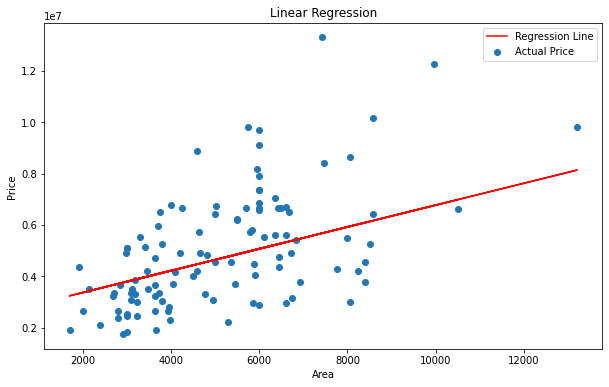

In [47]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test["area"], y_test,label="Actual Price")
plt.plot(X_test["area"], linear.predict(X_test), color="red",label="Regression Line")
plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Linear Regression")
plt.legend()
plt.show()

In [48]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)
poly_pred = poly_model.predict(X_test_poly)

In [49]:
poly_mse = mean_squared_error(y_test, poly_pred)
poly_mae = mean_absolute_error(y_test, poly_pred)
poly_r2 = r2_score(y_test, poly_pred)

print("Polynomial Regression (Degree =2)")
print("Coefficient:", poly_model.coef_)
print("Intercept:", poly_model.intercept_)
print("MSE:", poly_mse)
print("MAE:", poly_mae)
print("R2:", poly_r2)

Polynomial Regression (Degree =2)
Coefficient: [ 0.00000000e+00  1.00836674e+03 -4.34731082e-02]
Intercept: 874882.830317704
MSE: 3562004338819.1157
MAE: 1435042.809916779
R2: 0.2952903678835116


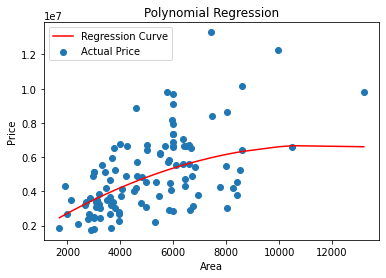

In [51]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test["area"], y_test, label="Actual Price")
a = X_test.sort_values(by="area")
plt.plot(a["area"], poly_model.predict(poly.transform(a)), color="red", label="Regression Curve")
plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Polynomial Regression")
plt.legend()
plt.show()

In [52]:
if poly_r2 > linear_r2:
    flag = "polynomial"
    print("Polynomial Regression has the higher R2 score")
else:
    flag = "linear"
    print("Linear Regression has the higher R2 score")

Polynomial Regression has the higher R2 score


In [54]:
new_area = float(input("Enter the area: "))

if flag == "polynomial":
    print("Polynomial Regression")
    pred_price = poly_model.predict(poly.transform([[new_area]]))[0]
else:
    print("Linear Regression")
    pred_price = linear.predict([[new_area]])[0]

print("Predicted Price:", round(pred_price, 2))

Enter the area: 444
Polynomial Regression
Predicted Price: 1314027.55


In [55]:
features = [
    "area",
    "bedrooms",
    "bathrooms",
    "stories",
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "parking",
    "prefarea",
    "furnishingstatus"
]

In [56]:
x = house[features]
y = house["price"]

In [57]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.30,
    random_state=0
)

In [58]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (381, 12)
Testing data: (164, 12)


In [59]:
from sklearn.preprocessing import StandardScaler

In [60]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Features scaled successfully")

Features scaled successfully


In [61]:
multiple = LinearRegression()
multiple.fit(x_train_scaled, y_train)
multiple_pred = multiple.predict(x_test_scaled)

print("Multiple Regression completed")

Multiple Regression completed


In [62]:
multiple_mse = mean_squared_error(y_test, multiple_pred)
multiple_mae = mean_absolute_error(y_test, multiple_pred)
multiple_r2 = r2_score(y_test, multiple_pred)

print("Multiple Regression")
print("Coefficients:", multiple.coef_)
print("Intercept:", multiple.intercept_)
print("MSE:", multiple_mse)
print("MAE:", multiple_mae)
print("R2:", multiple_r2)

Multiple Regression
Coefficients: [ 497856.1808794   103441.45329953  445613.58356278  361633.93955794
  160770.0708191   140593.7473326   168606.17755805  258694.67546633
  427545.32809597  188093.57459698  296188.47576599 -177169.63640041]
Intercept: 4768119.265091863
MSE: 982536031797.4524
MAE: 741860.8848593158
R2: 0.7167483728231432


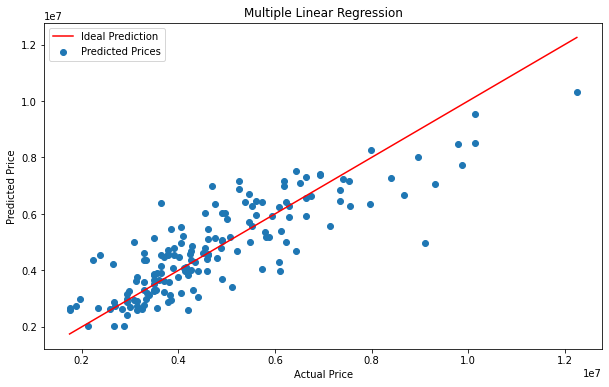

In [63]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, multiple_pred, label="Predicted Prices")
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], color="red", label="Ideal Prediction")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Multiple Linear Regression")
plt.legend()
plt.show()

In [ ]:
area = float(input("Enter area: "))
bedrooms = float(input("Enter bedrooms: "))
bathrooms = float(input("Enter bathrooms: "))
stories = float(input("Enter stories: "))
mainroad = int(input("Mainroad (1/0): "))
guestroom = int(input("Guestroom (1/0): "))
basement = int(input("Basement (1/0): "))
hotwaterheating = int(input("Hot water heating (1/0): "))
airconditioning = int(input("Air conditioning (1/0): "))
parking = float(input("Enter parking spaces: "))
prefarea = int(input("Preferred area (1/0): "))
furnishingstatus = int(input("Furnishing (0, 1, or 2): "))

user_data = pd.DataFrame([[
    area, bedrooms, bathrooms, stories, mainroad, guestroom,
    basement, hotwaterheating, airconditioning, parking,
    prefarea, furnishingstatus
]], columns=features)

price = multiple.predict(scaler.transform(user_data))
print("Predicted House Price:", round(price[0], 2))